
# Notebook 11: Handling Imbalanced Data

## Objective
Understand class imbalance and learn techniques to improve
machine learning performance on imbalanced classification datasets.

## Learning Outcomes
- Identify balanced and imbalanced datasets.
- Understand why class imbalance affects model evaluation.
- Apply random undersampling and oversampling.
- Apply SMOTE and Borderline-SMOTE.
- Use class weights to address class imbalance.
- Evaluate models using precision, recall, F1-score, and confusion matrices.
- Understand why accuracy alone can be misleading.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    balanced_accuracy_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
X, y = make_classification(
    n_samples=2000,
    n_features=10,
    n_informative=5,
    n_redundant=2,
    n_classes=2,
    weights=[0.95, 0.05],
    random_state=42
)

feature_columns = [f"Feature_{i}" for i in range(1, 11)]

df_imbalanced = pd.DataFrame(X, columns=feature_columns)
df_imbalanced["Target"] = y

print("Dataset shape:", df_imbalanced.shape)
print("\nClass counts:")
display(df_imbalanced["Target"].value_counts().sort_index())

print("\nFirst five rows:")
display(df_imbalanced.head())

Dataset shape: (2000, 11)

Class counts:


Target
0    1892
1     108
Name: count, dtype: int64


First five rows:


,Feature_1,Feature_2,Feature_3,Feature_4,Feature_5,Feature_6,Feature_7,Feature_8,Feature_9,Feature_10,Target
0,1.719421,-0.995037,1.347159,-0.105095,2.238050,0.120165,0.630093,0.341180,0.365803,-1.431276,0
1,1.628344,-0.526241,0.116202,1.399840,1.955209,0.610469,-0.102266,1.759813,0.484695,-1.058643,0
2,0.855182,1.525454,1.932957,-2.284388,-1.581202,1.583316,0.696688,-0.174947,-0.090593,0.141984,0
3,-0.007153,-0.589655,0.092564,0.956371,-1.073790,-0.219023,0.434362,-1.748067,-1.201759,1.585682,0
4,0.713820,-0.559466,-0.411422,-0.700216,2.681279,0.096479,0.373257,-0.193602,0.746925,-2.103692,0


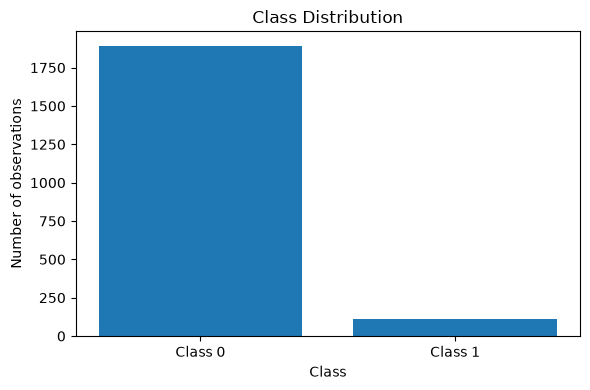

Class percentages:


Target
0    94.6
1     5.4
Name: Percentage, dtype: float64

In [3]:
class_counts = df_imbalanced["Target"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
plt.bar(
    ["Class 0", "Class 1"],
    [class_counts.get(0, 0), class_counts.get(1, 0)]
)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of observations")
plt.tight_layout()
plt.show()

print("Class percentages:")
display(
    (df_imbalanced["Target"].value_counts(normalize=True) * 100)
    .sort_index()
    .rename("Percentage")
    .round(2)
)


## 1. What Is Class Imbalance?

Class imbalance occurs when one target class has substantially
more observations than another.

Example:
- 95% of transactions are legitimate.
- 5% of transactions are fraudulent.

The majority class contains most observations, while the minority
class contains relatively few observations.

Class imbalance is common in fraud detection, disease screening,
equipment failure prediction, and rare-event classification.


In [4]:
y_true = np.array([0] * 95 + [1] * 5)

# A model predicts every observation as the majority class.
y_pred_majority = np.zeros(100, dtype=int)

print("Accuracy:", round(accuracy_score(y_true, y_pred_majority), 3))
print("Minority-class precision:",
      round(precision_score(y_true, y_pred_majority, zero_division=0), 3))
print("Minority-class recall:",
      round(recall_score(y_true, y_pred_majority, zero_division=0), 3))
print("Minority-class F1:",
      round(f1_score(y_true, y_pred_majority, zero_division=0), 3))

print("\nConfusion matrix:")
print(confusion_matrix(y_true, y_pred_majority))

Accuracy: 0.95
Minority-class precision: 0.0
Minority-class recall: 0.0
Minority-class F1: 0.0

Confusion matrix:
[[95  0]
 [ 5  0]]



## 3. Why Accuracy Alone Can Be Misleading

Accuracy measures the proportion of all predictions that are correct.

On an imbalanced dataset, a model can achieve high accuracy by
predicting the majority class for almost every observation.

Important alternative metrics include:

- Precision: Of the predicted positive cases, how many are positive?
- Recall: Of the actual positive cases, how many were detected?
- F1-score: The harmonic mean of precision and recall.
- Balanced accuracy: The average recall across classes.
- Confusion matrix: Shows true positives, true negatives,
  false positives, and false negatives.

Metric selection should reflect the real cost of missed detections
and false alarms.


In [5]:
X = df_imbalanced.drop(columns=["Target"])
y = df_imbalanced["Target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training class distribution:")
display(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
display(y_test.value_counts().sort_index())

Training class distribution:


Target
0    1514
1      86
Name: count, dtype: int64


Testing class distribution:


Target
0    378
1     22
Name: count, dtype: int64

In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (1600, 10)
Testing data shape: (400, 10)


Baseline classification report:
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       378
           1       0.00      0.00      0.00        22

    accuracy                           0.94       400
   macro avg       0.47      0.50      0.48       400
weighted avg       0.89      0.94      0.92       400



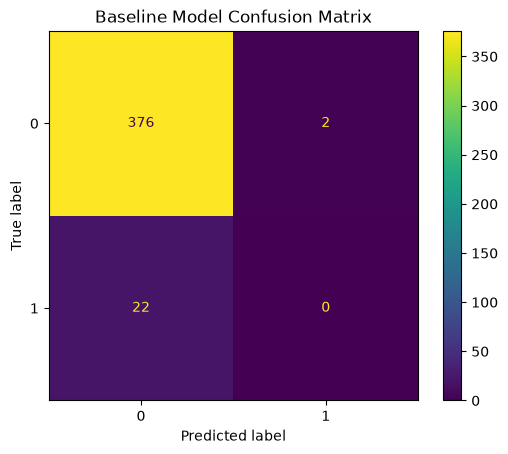

In [7]:
def evaluate_model(name, model, X_eval, y_eval):
    predictions = model.predict(X_eval)

    return {
        "Method": name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "Precision": precision_score(
            y_eval, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, zero_division=0
        ),
        "F1_Score": f1_score(
            y_eval, predictions, zero_division=0
        ),
        "Balanced_Accuracy": balanced_accuracy_score(
            y_eval, predictions
        )
    }


baseline_model = LogisticRegression(max_iter=1000, random_state=42)

baseline_model.fit(X_train_scaled, y_train)

baseline_predictions = baseline_model.predict(X_test_scaled)

print("Baseline classification report:")
print(classification_report(y_test, baseline_predictions, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_predictions
)
plt.title("Baseline Model Confusion Matrix")
plt.show()

In [8]:
%pip install imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [9]:
from imblearn.under_sampling import RandomUnderSampler

under_sampler = RandomUnderSampler(random_state=42)

X_under, y_under = under_sampler.fit_resample(
    X_train_scaled, y_train
)

print("Class counts before undersampling:")
display(y_train.value_counts().sort_index())

print("\nClass counts after undersampling:")
display(pd.Series(y_under).value_counts().sort_index())

under_model = LogisticRegression(max_iter=1000, random_state=42)
under_model.fit(X_under, y_under)

print("\nUndersampling results:")
print(classification_report(
    y_test,
    under_model.predict(X_test_scaled),
    zero_division=0
))

Class counts before undersampling:


Target
0    1514
1      86
Name: count, dtype: int64


Class counts after undersampling:


Target
0    86
1    86
Name: count, dtype: int64


Undersampling results:
              precision    recall  f1-score   support

           0       0.98      0.71      0.82       378
           1       0.13      0.73      0.22        22

    accuracy                           0.71       400
   macro avg       0.55      0.72      0.52       400
weighted avg       0.93      0.71      0.79       400



In [10]:
from imblearn.over_sampling import RandomOverSampler

over_sampler = RandomOverSampler(random_state=42)

X_over, y_over = over_sampler.fit_resample(
    X_train_scaled, y_train
)

print("Class counts after random oversampling:")
display(pd.Series(y_over).value_counts().sort_index())

over_model = LogisticRegression(max_iter=1000, random_state=42)
over_model.fit(X_over, y_over)

print("\nRandom oversampling results:")
print(classification_report(
    y_test,
    over_model.predict(X_test_scaled),
    zero_division=0
))

Class counts after random oversampling:


Target
0    1514
1    1514
Name: count, dtype: int64


Random oversampling results:
              precision    recall  f1-score   support

           0       0.97      0.73      0.83       378
           1       0.11      0.59      0.19        22

    accuracy                           0.72       400
   macro avg       0.54      0.66      0.51       400
weighted avg       0.92      0.72      0.80       400



In [11]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42, k_neighbors=5)

X_smote, y_smote = smote.fit_resample(
    X_train_scaled, y_train
)

print("Class counts after SMOTE:")
display(pd.Series(y_smote).value_counts().sort_index())

smote_model = LogisticRegression(max_iter=1000, random_state=42)
smote_model.fit(X_smote, y_smote)

print("\nSMOTE results:")
print(classification_report(
    y_test,
    smote_model.predict(X_test_scaled),
    zero_division=0
))

Class counts after SMOTE:


Target
0    1514
1    1514
Name: count, dtype: int64


SMOTE results:
              precision    recall  f1-score   support

           0       0.97      0.73      0.83       378
           1       0.11      0.59      0.19        22

    accuracy                           0.72       400
   macro avg       0.54      0.66      0.51       400
weighted avg       0.92      0.72      0.80       400



In [12]:
from imblearn.over_sampling import BorderlineSMOTE

borderline_smote = BorderlineSMOTE(random_state=42)

X_borderline, y_borderline = borderline_smote.fit_resample(
    X_train_scaled, y_train
)

print("Class counts after Borderline-SMOTE:")
display(pd.Series(y_borderline).value_counts().sort_index())

borderline_model = LogisticRegression(max_iter=1000, random_state=42)
borderline_model.fit(X_borderline, y_borderline)

print("\nBorderline-SMOTE results:")
print(classification_report(
    y_test,
    borderline_model.predict(X_test_scaled),
    zero_division=0
))

Class counts after Borderline-SMOTE:


Target
0    1514
1    1514
Name: count, dtype: int64


Borderline-SMOTE results:
              precision    recall  f1-score   support

           0       0.97      0.77      0.86       378
           1       0.14      0.64      0.23        22

    accuracy                           0.76       400
   macro avg       0.56      0.70      0.54       400
weighted avg       0.93      0.76      0.82       400



Class-weighted classification report:
              precision    recall  f1-score   support

           0       0.97      0.72      0.83       378
           1       0.12      0.68      0.21        22

    accuracy                           0.72       400
   macro avg       0.55      0.70      0.52       400
weighted avg       0.93      0.72      0.79       400



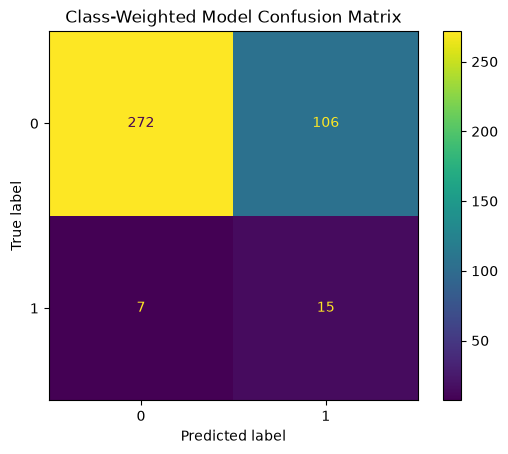

In [13]:
weighted_model = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

weighted_model.fit(X_train_scaled, y_train)

weighted_predictions = weighted_model.predict(X_test_scaled)

print("Class-weighted classification report:")
print(classification_report(
    y_test,
    weighted_predictions,
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    weighted_predictions
)
plt.title("Class-Weighted Model Confusion Matrix")
plt.show()

In [14]:
results = []

results.append(
    evaluate_model(
        "Baseline",
        baseline_model,
        X_test_scaled,
        y_test
    )
)

results.append(
    evaluate_model(
        "Random Undersampling",
        under_model,
        X_test_scaled,
        y_test
    )
)

results.append(
    evaluate_model(
        "Random Oversampling",
        over_model,
        X_test_scaled,
        y_test
    )
)

results.append(
    evaluate_model(
        "SMOTE",
        smote_model,
        X_test_scaled,
        y_test
    )
)

results.append(
    evaluate_model(
        "Borderline-SMOTE",
        borderline_model,
        X_test_scaled,
        y_test
    )
)

results.append(
    evaluate_model(
        "Class Weights",
        weighted_model,
        X_test_scaled,
        y_test
    )
)

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1_Score",
        ascending=False
    ).round(3)
)

,Method,Accuracy,Precision,Recall,F1_Score,Balanced_Accuracy
4,Borderline-SMOTE,0.762,0.139,0.636,0.228,0.703
1,Random Undersampling,0.710,0.127,0.727,0.216,0.718
5,Class Weights,0.718,0.124,0.682,0.210,0.701
3,SMOTE,0.720,0.112,0.591,0.188,0.659
2,Random Oversampling,0.720,0.112,0.591,0.188,0.659
0,Baseline,0.940,0.000,0.000,0.000,0.497


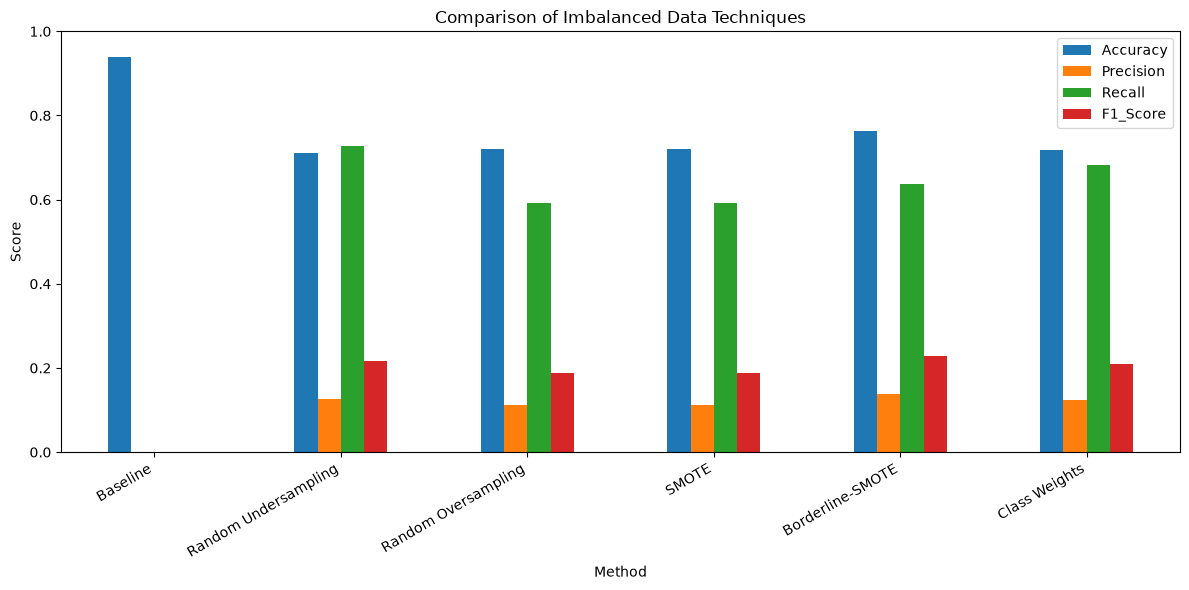

In [15]:
results_df.set_index("Method")[
    ["Accuracy", "Precision", "Recall", "F1_Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Comparison of Imbalanced Data Techniques")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## Summary: Handling Imbalanced Data

| Technique | When to use | Main limitation |
|---|---|---|
| Random undersampling | Very large majority class | Loses majority information |
| Random oversampling | Small minority class | Can overfit repeated examples |
| SMOTE | Numerical data with useful minority neighborhoods | May create unrealistic samples |
| Borderline-SMOTE | Difficult minority examples near the boundary | Sensitive to noise and overlap |
| Class weights | Prefer weighting errors instead of resampling | May increase false positives |

Always split the data before resampling and apply resampling only
to the training set. Evaluate the final model on untouched data
that reflects the intended real-world class distribution.



## Conclusion

In this notebook, I learned what class imbalance is and why
imbalanced classification requires careful evaluation.

I applied random undersampling, random oversampling, SMOTE,
Borderline-SMOTE, and class weighting.

I compared models using accuracy, precision, recall, F1-score,
balanced accuracy, and confusion matrices.

I learned that high accuracy can hide poor minority-class
detection and that the correct technique depends on the dataset,
the cost of classification errors, and the business objective.

Resampling must be restricted to training data to avoid leakage.
The final evaluation should use untouched data with realistic
class proportions.
